# Method C: spectrogram ridge with a cardiac notch, and learning from beam features

Method C has two parts. The first tracks the breathing rate through a recording instead of giving one number per window: a spectrogram of the phase rate, the heart frequency notched out, and a ridge through the breathing band. The second asks whether a model can learn the rates from the beams directly, with three architectures on the same features: a dense network, a stacked LSTM on the beam sequence, and a hybrid of both.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=["#1b4965", "#c8553d", "#5c946e", "#8c6d9f"])})
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from radar import beams, cube, learn, simulate, vitals

p = simulate.Person(1.8, 0, rr=10, rr_end=26, hr=52, resp_mm=3.0,
                    motion=[(30, 6, 30.0), (75, 5, 24.0), (110, 6, 30.0)])
x, truth = simulate.simulate([p], duration=150, clutter=[(1.4, 0, 3.0), (1.8, 0, 0.8)], snr_db=18, seed=7)
cfg, fs, t = truth["config"], truth["config"].frame_rate, truth["t"]
rp = cube.compensate_aop(cube.range_fft(x))
z = rp[:, :, :, int(round(1.8 / cfg.range_resolution))].mean(axis=(1, 2))
centre = vitals.circle_fit(z)[0]
rate = np.gradient(vitals.phase(z, centre)) * fs / (2 * np.pi)       # phase rate, Hz

## Ridge tracking

The spectrogram $S(f,\tau)$ of the phase rate is computed on 15 s windows moved by 2 s. Taking the largest value of each column inside the breathing band gives a rate per window, but one column where a harmonic or a burst of body motion wins is enough to make the track jump. The person below shifts in bed three times (shaded), moving the chest by up to 3 cm for five to six seconds. `vitals.ridge` instead chooses the path $f_1,\dots,f_J$ through the columns that maximises
$$
\sum_j \log S(f_j,\tau_j) \;-\; \sum_j \left(\frac{f_j-f_{j-1}}{\Delta}\right)^2 ,
$$
solved exactly by dynamic programming, with $\Delta$ the change in rate per step that is considered plausible (6 per minute here).

**Cardiac notch.** Differentiation lifts the heartbeat, and a slow heart sits close to the breathing band: at 52 per minute it is at 0.87 Hz, 0.17 Hz above the top of the band, which a 15 s Hann window still smears into the band, together with the beat-to-beat variability. Method C first estimates the heart rate on a quiet stretch, then removes it and its harmonics with notch filters (`vitals.notch_harmonics`) before the spectrogram is formed.

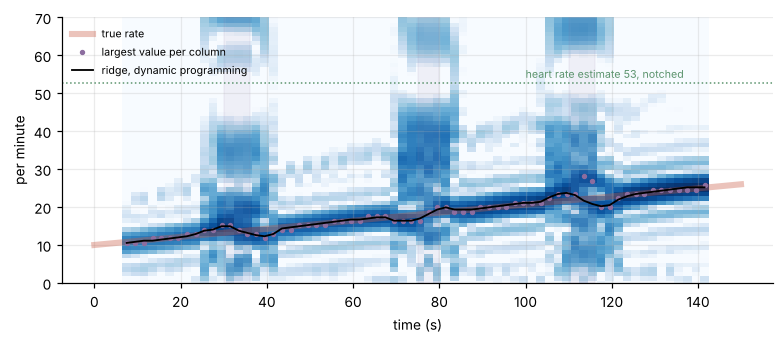

In [2]:
from scipy.signal import spectrogram
_, hr_est = vitals.vital_rates(z[: int(25 * fs)], fs, centre=centre)      # quiet first 25 s
clean = vitals.notch_harmonics(rate, fs, hr_est / 60, n=3, q=4)
band = (0.05, 0.7)
tr, rr_dp = vitals.ridge(clean, fs, band, win_s=15, step_s=2, max_step=6)
f, ts, S = spectrogram(clean, fs=fs, nperseg=int(15 * fs), noverlap=int(13 * fs), nfft=1024, detrend="linear")
m = (f >= band[0]) & (f <= band[1])
rr_max = 60 * f[m][np.argmax(S[m], axis=0)]

fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.pcolormesh(ts, 60 * f, 10 * np.log10(S / S.max() + 1e-9), vmin=-25, cmap="Blues", shading="auto")
ax.plot(t, np.linspace(10, 26, len(t)), color="#c8553d", lw=4, alpha=0.35, label="true rate")
ax.plot(ts, rr_max, "o", ms=2.5, color="#8c6d9f", label="largest value per column")
ax.plot(tr, rr_dp, color="k", lw=1.2, label="ridge, dynamic programming")
ax.axhline(hr_est, color="#5c946e", ls=":", lw=1)
ax.text(100, hr_est + 1.5, f"heart rate estimate {hr_est:.0f}, notched", fontsize=7, color="#5c946e")
for t0, dur, _ in p.motion:
    ax.axvspan(t0, t0 + dur, color="#8c6d9f", alpha=0.08)
ax.set(ylim=(0, 70), xlabel="time (s)", ylabel="per minute")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()

## Learning from the beams

The second part of Method C treats every beam as an example and the simulator settings as targets. `learn.beam_features` describes a beam with amplitude statistics (how strong and stable the echo is), phase-rate statistics (how much the chest moves), the fraction of power, the dominant frequency and the spectral entropy in the breathing and heart bands, and the rates found by the signal processing chain itself, so that a model can learn when to trust them. For the recurrent models, `learn.beam_sequence` resamples the normalised phase rate and amplitude to a fixed length.

Below, the features of the three MVDR beams of the scene in Method A.

In [3]:
from radar import spatial
people = [simulate.Person(2.0, -25, rr=14, hr=80), simulate.Person(2.0, 20, rr=22, hr=90, amp=0.8),
          simulate.Person(2.6, 5, rr=20, hr=110, amp=0.9)]
x3, tr3 = simulate.simulate(people, duration=60, clutter=[(1.2, 0, 3.0), (3.5, -40, 2.0)], snr_db=20)
rp3 = cube.compensate_aop(cube.range_fft(x3))
targets = [(int(round(q.range_m / cfg.range_resolution)), q.azimuth_deg) for q in people]
B = beams.beams_for_targets(rp3, targets, cube.aop_positions(), kind="mvdr")
feats = [learn.beam_features(B[:, k], fs) for k in range(B.shape[1])]
names = list(feats[0])
print(f"{'feature':16s}" + "".join(f"  beam {k + 1:d}  " for k in range(3)))
for n in names:
    print(f"{n:16s}" + "".join(f"{fe[n]:10.3f}" for fe in feats))

feature           beam 1    beam 2    beam 3  
amp_mean             0.009     0.007     0.016
amp_cv               0.123     0.208     0.062
phase_std            3.516     3.495     3.503
rate_std             6.240     9.005     8.011
rate_kurtosis        2.334     2.231     1.977
rr_power             0.992     0.981     0.991
rr_peak_hz           0.250     0.350     0.350
rr_entropy           0.374     0.355     0.367
hr_power             0.006     0.008     0.004
hr_peak_hz           1.350     1.500     1.850
hr_entropy           0.587     0.615     0.413
rr_spectral         14.028    21.998    19.924
rr_zero_cross       14.000    21.500    19.500
hr_spectral         79.767    89.725   110.490


Three architectures, all with a Huber loss so that a few beams pointed at the wrong person do not dominate the gradient:

- `learn.dense_model`: two dense layers on the features (this is also Method E, which adds batch normalisation, dropout and mixup);
- `learn.lstm_model`: two stacked LSTM layers on the beam sequence;
- `learn.hybrid_model`: the LSTM branch and a small dense branch for the features, concatenated before the output.

In [4]:
seq = learn.beam_sequence(B[:, 0], fs)
for name, model in [("dense", learn.dense_model(len(names))),
                    ("LSTM", learn.lstm_model(*seq.shape)),
                    ("hybrid", learn.hybrid_model(*seq.shape, len(names)))]:
    print(f"{name:7s} parameters: {model.count_params():6d}   inputs: {[tuple(i.shape[1:]) for i in model.inputs]}")

dense   parameters:   3329   inputs: [(14,)]
LSTM    parameters:   7761   inputs: [(256, 2)]
hybrid  parameters:   8145   inputs: [(256, 2), (14,)]


## How to evaluate them

Two rules decide whether a number from these models means anything.

- **Split by recording, not by beam.** The beams of one recording share the radar position, the room and the moment of acquisition, and with patient simulators they often share the condition too. A random split of beams puts parts of the same recording on both sides and the test error then measures how well the model remembers a recording. `learn.group_split` keeps every recording on one side; with few recordings, leave-one-recording-out cross-validation is the honest alternative.
- **Standardise the targets.** Heart rates of 50 to 160 per minute fed to a network that starts with outputs near zero give an initial error above 100 and a long first phase of training spent only learning the mean. `learn.Scaler` standardises features and targets with training statistics and inverts the predictions afterwards.

With patient simulators the targets also take only a handful of values, one per clinical condition. A model can then reach a low error by recognising the condition from the beam rather than by measuring a rate, so the error should be read per condition and compared with the signal processing chain on the same recordings.

In [5]:
recording = np.repeat(np.arange(10), 3)            # e.g. 10 recordings with 3 beams each
train, test = learn.group_split(recording, test_size=0.3)
print("recordings in training:", sorted(set(recording[train].tolist())))
print("recordings in test:    ", sorted(set(recording[test].tolist())))

recordings in training: [0, 1, 3, 5, 6, 7, 9]
recordings in test:     [2, 4, 8]
